# Training Progress — All Runs

Auto-discovers all runs under `results/directory`, groups by method, plots loss curves and CMMD history.

In [1]:
import os, json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
import yaml
from pathlib import Path
from collections import defaultdict

RUNS_DIR = Path("results/directory")

def load_run(run_dir):
    run_dir = Path(run_dir)
    result = {"name": run_dir.name, "path": run_dir}
    cfg_path = run_dir / "config.yaml"
    if cfg_path.exists():
        with open(cfg_path) as f:
            result["config"] = yaml.safe_load(f)
    metrics_path = run_dir / "metrics.json"
    if metrics_path.exists():
        with open(metrics_path) as f:
            result["metrics"] = json.load(f)
    loss_path = run_dir / "loss_history.npz"
    if loss_path.exists():
        result["loss"] = np.load(loss_path)
    eval_path = run_dir / "eval_history.npz"
    if eval_path.exists():
        result["eval"] = np.load(eval_path)
    return result

runs = [load_run(d) for d in sorted(RUNS_DIR.iterdir()) if d.is_dir()]
print(f"Found {len(runs)} runs")

# Group by method
by_method = defaultdict(list)
for r in runs:
    method = r.get("config", {}).get("method", "unknown")
    by_method[method].append(r)

for method, rs in sorted(by_method.items()):
    seeds = [r.get("config", {}).get("seed", "?") for r in rs]
    print(f"  {method}: {len(rs)} runs  (seeds: {seeds})")

Found 16 runs
  dm: 5 runs  (seeds: [123, 1234, 2024, 42, 777])
  dmf: 5 runs  (seeds: [123, 1234, 2024, 42, 777])
  ofm: 5 runs  (seeds: [123, 42, 777, 1234, 2024])
  unknown: 1 runs  (seeds: ['?'])


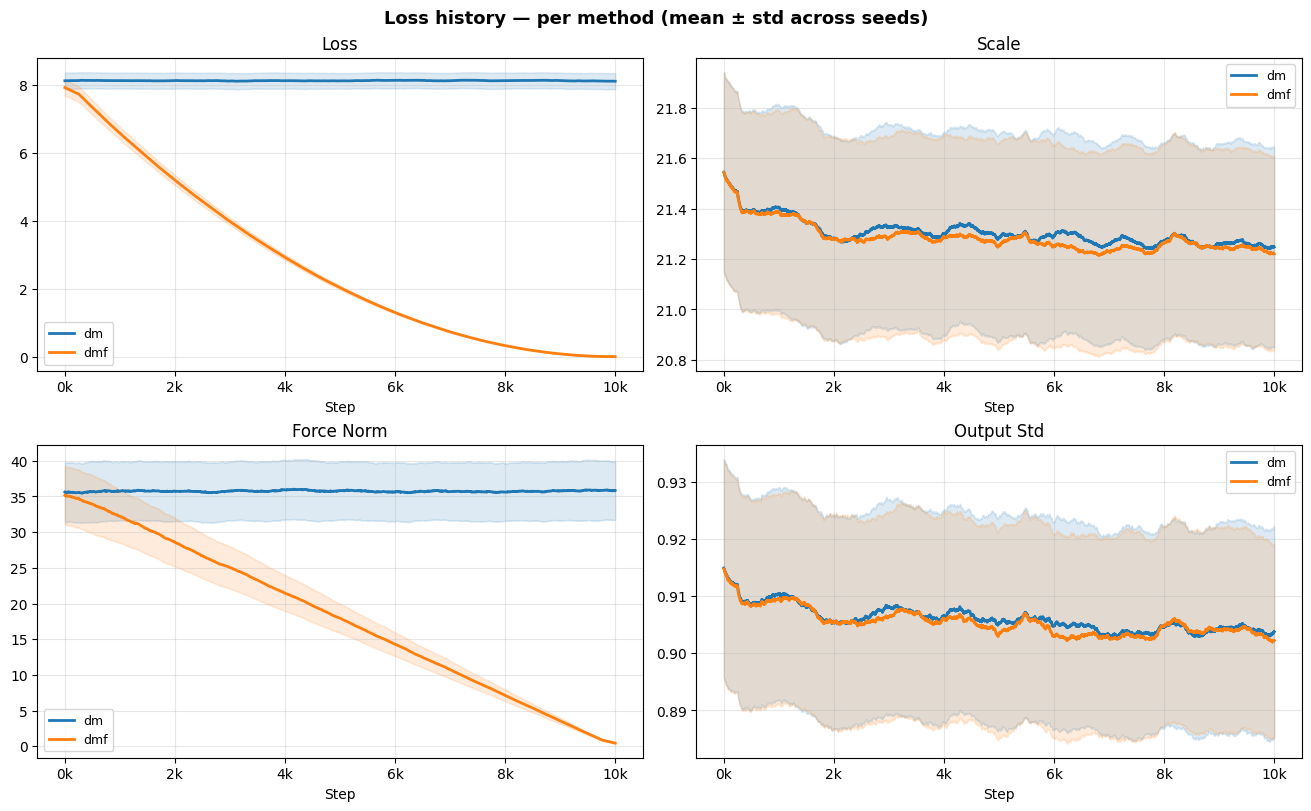

In [2]:
METHOD_COLORS = {
    "dm":  "tab:blue",
    "dmf": "tab:orange",
    "ofm": "tab:green",
}

def smooth(x, w=500):
    return pd.Series(x).rolling(w, center=True, min_periods=1).mean().to_numpy()

LOSS_KEYS = [
    ("loss",       "Loss"),
    ("scale",      "Scale"),
    ("force_norm", "Force Norm"),
    ("y_std",      "Output Std"),
]

methods = sorted(by_method.keys())
n_cols = min(2, len(LOSS_KEYS))
n_rows = (len(LOSS_KEYS) + 1) // 2

fig, axes = plt.subplots(n_rows, n_cols, figsize=(13, 4 * n_rows), constrained_layout=True)
fig.suptitle("Loss history — per method (mean ± std across seeds)", fontsize=13, fontweight="bold")
axes = np.array(axes).flat

for ax, (key, label) in zip(axes, LOSS_KEYS):
    for method in methods:
        color = METHOD_COLORS.get(method, None)
        arrays = []
        step_ref = None
        for r in by_method[method]:
            if "loss" not in r or key not in r["loss"]:
                continue
            step_ref = r["loss"]["step"]
            arrays.append(r["loss"][key])
        if not arrays:
            continue
        # align to shortest run
        min_len = min(len(a) for a in arrays)
        arrays = np.array([a[:min_len] for a in arrays])
        steps = step_ref[:min_len]
        mean = smooth(arrays.mean(axis=0))
        std  = smooth(arrays.std(axis=0))
        ax.plot(steps, mean, color=color, linewidth=2, label=method)
        ax.fill_between(steps, mean - std, mean + std, color=color, alpha=0.15)
    ax.set_title(label)
    ax.set_xlabel("Step")
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.show()

## Val CMMD vs Step

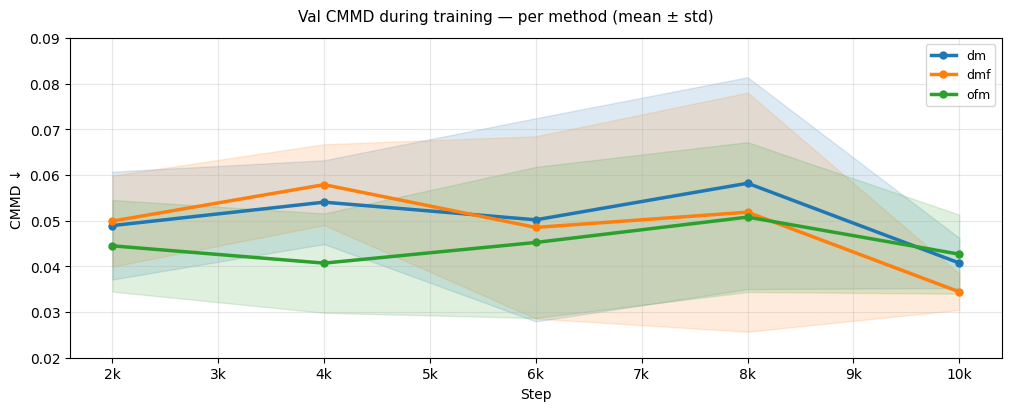

In [3]:
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
fig.suptitle("Val CMMD during training — per method (mean ± std)", fontsize=11)

for method in methods:
    color = METHOD_COLORS.get(method, None)
    eval_runs = [r for r in by_method[method] if "eval" in r]
    if not eval_runs:
        continue
    # individual runs (faint)
    for r in eval_runs:
        ax.plot(r["eval"]["step"], r["eval"]["cmmd"],
                color=color, alpha=0, linewidth=1, marker="o", markersize=2)
    # mean across seeds
    min_len = min(len(r["eval"]["step"]) for r in eval_runs)
    steps = eval_runs[0]["eval"]["step"][:min_len]
    cmmds = np.array([r["eval"]["cmmd"][:min_len] for r in eval_runs])
    mean = cmmds.mean(axis=0)
    std  = cmmds.std(axis=0)
    ax.plot(steps, mean, color=color, linewidth=2.5, marker="o", markersize=5, label=method)
    ax.fill_between(steps, mean - std, mean + std, color=color, alpha=0.15)

ax.set_ylabel("CMMD ↓")
ax.set_xlabel("Step")
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_ylim([0.02,0.09])
plt.savefig("cmmd_history.pdf",bbox_inches="tight")
plt.show()